# Random Forest: phishing emails


## 1. Imports and data

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# 10 toy emails: [num_links, urgent_words, sender_known], label +1 = phishing, -1 = legit
X_toy = np.array([[6,1,0],[4,1,0],[8,0,0],[5,0,1],[1,1,1],
                  [0,0,1],[2,0,1],[3,1,1],[1,0,0],[2,0,1]])
y_toy = np.array([1,1,1,1,1,-1,-1,-1,-1,-1])
features = ["num_links", "urgent_words", "sender_known"]

# 290 more emails from a scoring rule + noise
rng = np.random.default_rng(0)
n = 290
num_links = rng.integers(0, 10, n)
urgent = rng.integers(0, 2, n)
known = rng.integers(0, 2, n)
score = 0.5*num_links + 1.5*urgent - 2*known + rng.normal(0, 1.5, n)
X = np.vstack([X_toy, np.column_stack([num_links, urgent, known])])
y = np.concatenate([y_toy, np.where(score > 2, 1, -1)])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
print("train:", X_train.shape, " test:", X_test.shape)

train: (210, 3)  test: (90, 3)


## 2. The Random Forest class


In [ ]:
class RandomForest:
    def __init__(self, n_trees=100, max_depth=None, min_samples_split=2,
                 n_features="sqrt", sample_size=1.0):
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.n_features = n_features
        self.sample_size = sample_size
        self.trees = []

    def teach(self, X, y):
        self.trees = []
        for _ in range(self.n_trees):
            tree = DecisionTreeClassifier(max_depth=self.max_depth,   # sklearn's tree
                                          min_samples_split=self.min_samples_split,
                                          max_features=self.n_features)
            X_sample, y_sample = self._bootstrap_samples(X, y)
            tree.fit(X_sample, y_sample)
            self.trees.append(tree)
        return self

    def _bootstrap_samples(self, X, y):
        n_samples = X.shape[0]
        n_draws = int(self.sample_size * n_samples)
        idxs = np.random.choice(n_samples, n_draws, replace=True)
        return X[idxs], y[idxs]

    def vote(self, y):
        counter = Counter(y)
        most_common = counter.most_common(1)[0][0]
        return most_common

    def decide(self, X):
        predictions = np.array([tree.predict(X) for tree in self.trees])
        tree_preds = np.swapaxes(predictions, 0, 1)
        predictions = np.array([self.vote(pred) for pred in tree_preds])
        return predictions

## 3. Train and test

In [ ]:
def test(y_true, y_pred):
    accuracy = np.sum(y_true == y_pred) / len(y_true)
    return accuracy

np.random.seed(42)                       #same random choices every run
my_forest = RandomForest(n_trees=100)
my_forest.teach(X_train, y_train)
predictions = my_forest.decide(X_test)

acc = test(y_test, predictions)
print("my forest:", acc)

my forest: 0.8111111111111111


## 4. Picture: three trees from the forest

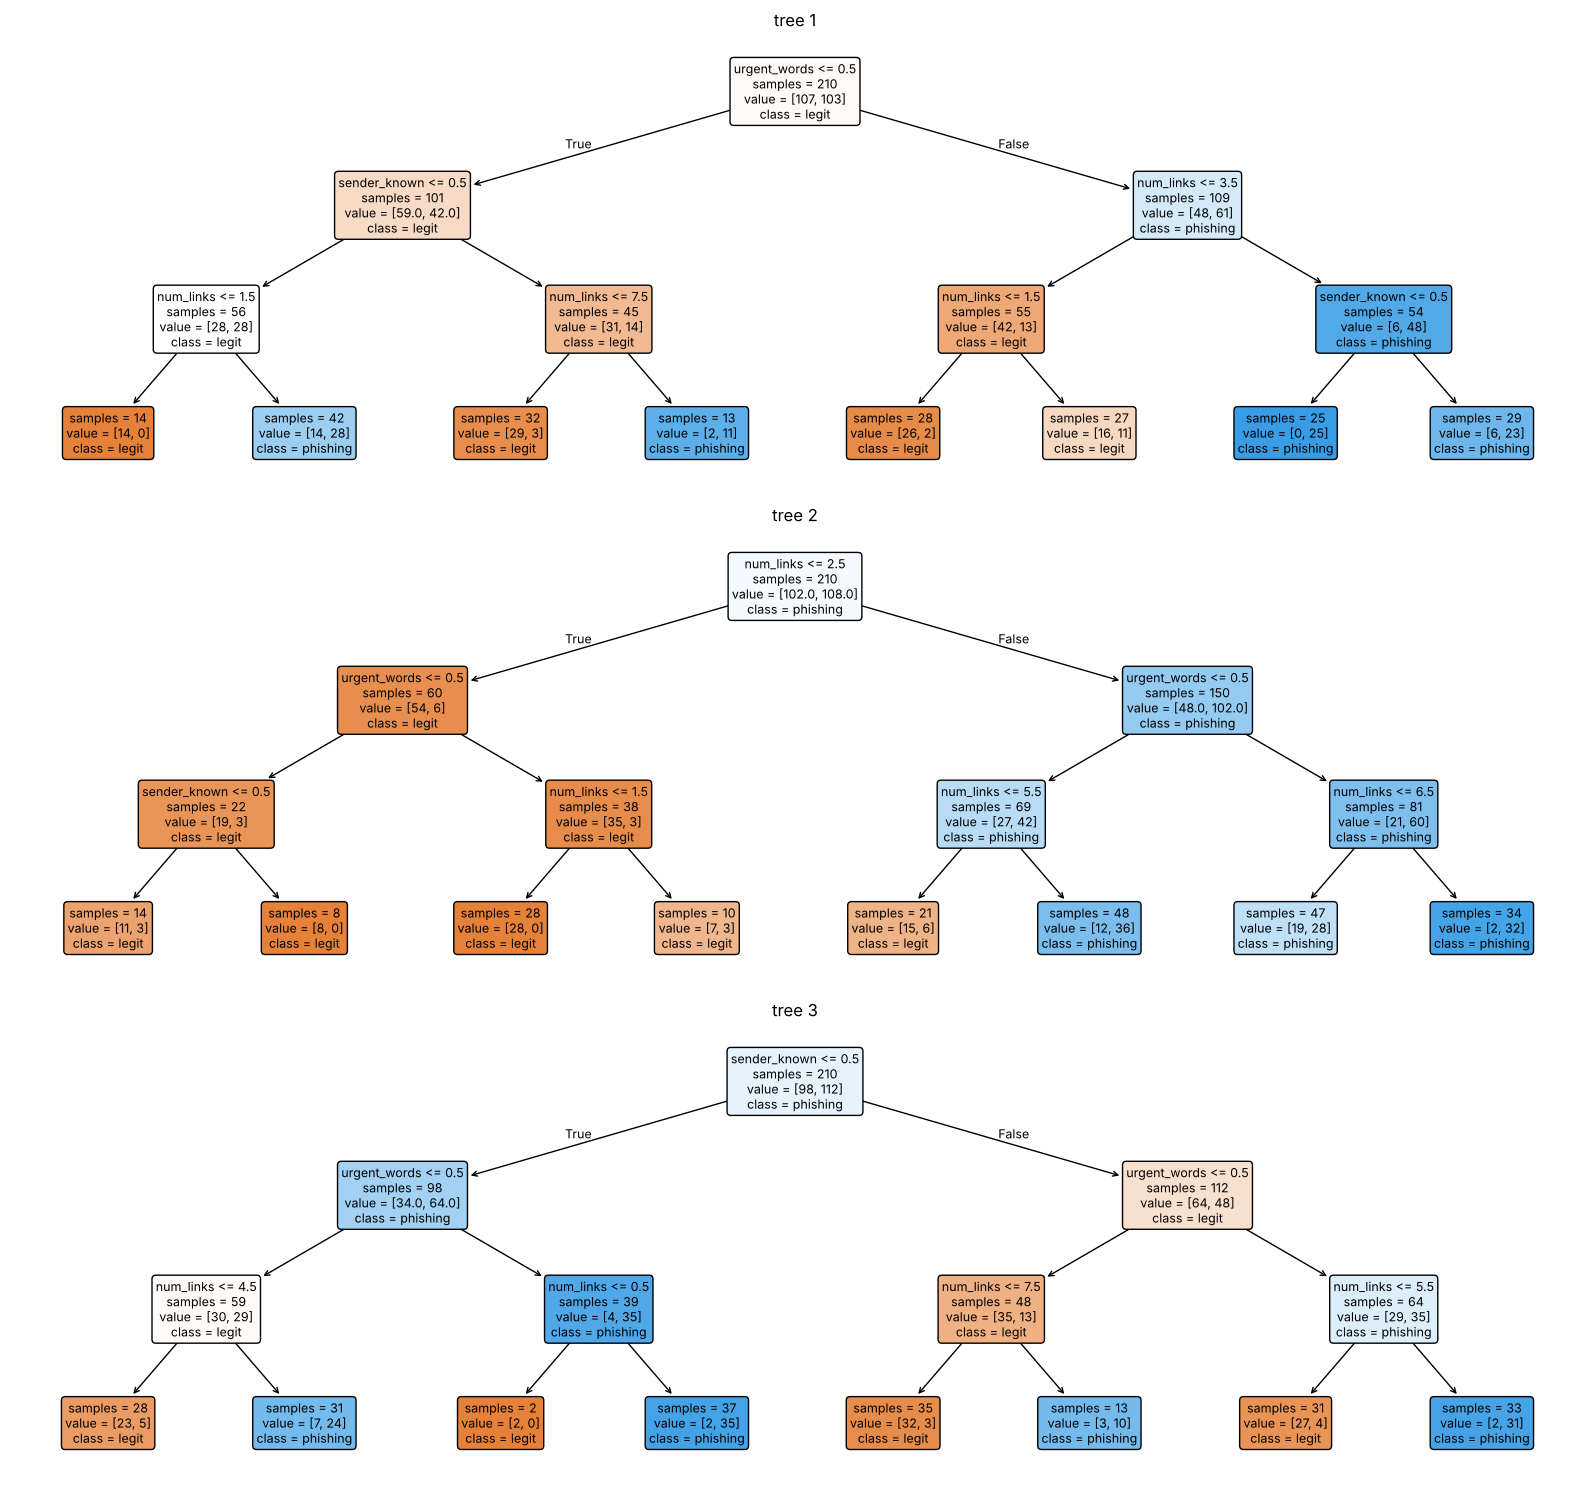

In [ ]:
np.random.seed(7)
small = RandomForest(n_trees=3, max_depth=3).teach(X_train, y_train)

fig, axes = plt.subplots(3, 1, figsize=(16, 15))
for i, ax in enumerate(axes):
    plot_tree(small.trees[i], feature_names=features, class_names=["legit", "phishing"],
              filled=True, rounded=True, impurity=False, fontsize=9, ax=ax)
    ax.set_title(f"tree {i + 1}")
plt.tight_layout(); plt.show()

The three trees start with **different first questions** (urgent words, number of links, sender known), because each one got different emails (bootstrap) and different random features at each split. That difference is why voting helps.

## 5. Comparison with sklearn

In [ ]:
np.random.seed(42)
my_forest = RandomForest(n_trees=100).teach(X_train, y_train)
sk = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
one_tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

print("one tree        :", round(test(y_test, one_tree.predict(X_test)), 3))
print("my forest       :", round(test(y_test, my_forest.decide(X_test)), 3))
print("sklearn forest  :", round(test(y_test, sk.predict(X_test)), 3))
print("same prediction :", round(np.mean(my_forest.decide(X_test) == sk.predict(X_test)), 3))

one tree        : 0.811
my forest       : 0.811
sklearn forest  : 0.822
same prediction : 0.967


- Both forests get almost the same accuracy and agree on almost every email. They are not exactly equal because the random numbers are different.
- Here one tree is as good as the forest, because my data is very simple: only 3 features, so only 40 possible different emails. A forest helps more when there are many features.
- Nobody reaches 100 %: the data has noise (some emails look like phishing but are legit).

## 6. Hyperparameter analysis (NEW)
The lecture names 3 Random Forest hyperparameters (settings chosen **before** training):

| lecture name | my forest | sklearn | controls |
|---|---|---|---|
| number of trees | `n_trees` | `n_estimators` | how many trees vote |
| sample size | `sample_size` | `max_samples` | how many emails each tree gets (**randomness 1**) |
| size of the feature subset | `n_features` | `max_features` | how many features each split may use (**randomness 2**) |

For each value I train the forest **5 times** (different random seeds) and take the **average** test accuracy, so luck matters less. I do the same for sklearn's forest.

In [ ]:
def avg_accuracy(**settings):
    # my forest: 5 runs with different seeds, average test accuracy
    scores = []
    for seed in range(5):
        np.random.seed(seed)
        my_forest = RandomForest(**settings).teach(X_train, y_train)
        scores.append(test(y_test, my_forest.decide(X_test)))
    return np.mean(scores)

def avg_accuracy_sklearn(**settings):
    # sklearn's forest: the same, 5 runs, average test accuracy
    scores = []
    for seed in range(5):
        sk = RandomForestClassifier(random_state=seed, **settings).fit(X_train, y_train)
        scores.append(test(y_test, sk.predict(X_test)))
    return np.mean(scores)

### 6.1 Number of trees

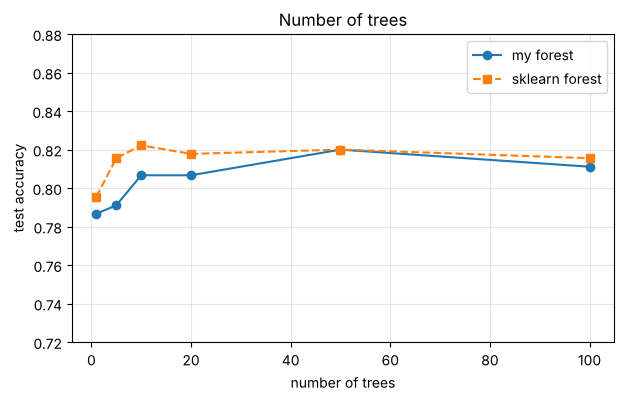

   1 trees   my forest 0.787   sklearn 0.796
   5 trees   my forest 0.791   sklearn 0.816
  10 trees   my forest 0.807   sklearn 0.822
  20 trees   my forest 0.807   sklearn 0.818
  50 trees   my forest 0.820   sklearn 0.820
 100 trees   my forest 0.811   sklearn 0.816


In [ ]:
tree_list = [1, 5, 10, 20, 50, 100]
mine_trees = [avg_accuracy(n_trees=t) for t in tree_list]
sk_trees = [avg_accuracy_sklearn(n_estimators=t) for t in tree_list]

plt.figure(figsize=(7, 4))
plt.plot(tree_list, mine_trees, "o-", label="my forest")
plt.plot(tree_list, sk_trees, "s--", label="sklearn forest")
plt.xlabel("number of trees"); plt.ylabel("test accuracy"); plt.title("Number of trees")
plt.ylim(0.72, 0.88); plt.grid(alpha=0.3); plt.legend(); plt.show()

for t, a, b in zip(tree_list, mine_trees, sk_trees):
    print(f"{t:>4} trees   my forest {a:.3f}   sklearn {b:.3f}")

**What we see:**
- With **1 tree**: about **79–80 %**. With **10 trees**: about **81–82 %**. After that the line is **flat**.
- My forest and sklearn's forest show the **same pattern**.

**Why:** more trees make the vote more stable, but after about 10–20 trees there is nothing more to gain on our simple data. More trees **never hurt** the accuracy (no overfitting); they only cost more time.


### 6.2 Sample size

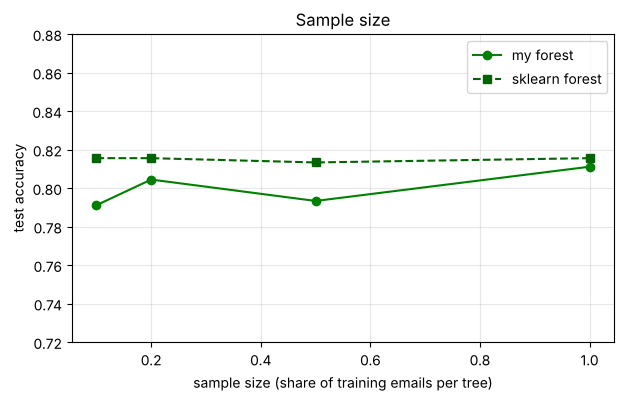

  10 %   my forest 0.791   sklearn 0.816
  20 %   my forest 0.804   sklearn 0.816
  50 %   my forest 0.793   sklearn 0.813
 100 %   my forest 0.811   sklearn 0.816


In [ ]:
size_list = [0.1, 0.2, 0.5, 1.0]
mine_size = [avg_accuracy(sample_size=s) for s in size_list]
sk_size = [avg_accuracy_sklearn(max_samples=s) for s in size_list]

plt.figure(figsize=(7, 4))
plt.plot(size_list, mine_size, "o-", color="green", label="my forest")
plt.plot(size_list, sk_size, "s--", color="darkgreen", label="sklearn forest")
plt.xlabel("sample size (share of training emails per tree)"); plt.ylabel("test accuracy"); plt.title("Sample size")
plt.ylim(0.72, 0.88); plt.grid(alpha=0.3); plt.legend(); plt.show()

for s, a, b in zip(size_list, mine_size, sk_size):
    print(f"{int(s * 100):>4} %   my forest {a:.3f}   sklearn {b:.3f}")

**What we see:**
- My forest: **79–81 %** for all sample sizes; 100 % is slightly the best.
- sklearn: about **81–82 %**, almost flat.
- Even with only **10 %** of the emails per tree, the forest still works well.

**Why:** a smaller sample makes the trees **more different** from each other (good for voting) but each tree is **weaker**, because it learns from fewer emails. On our data these two effects roughly cancel out. 100 % (the classic choice) is a safe default.

### 6.3 Size of the feature subset

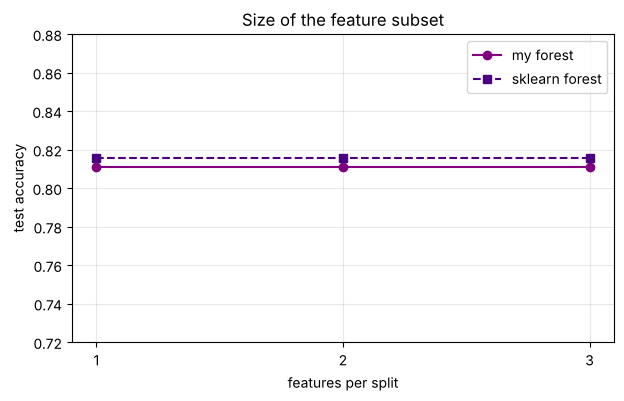

1 features   my forest 0.811   sklearn 0.816
2 features   my forest 0.811   sklearn 0.816
3 features   my forest 0.811   sklearn 0.816


In [ ]:
feat_list = [1, 2, 3]
mine_feat = [avg_accuracy(n_features=f) for f in feat_list]
sk_feat = [avg_accuracy_sklearn(max_features=f) for f in feat_list]

plt.figure(figsize=(7, 4))
plt.plot(feat_list, mine_feat, "o-", color="purple", label="my forest")
plt.plot(feat_list, sk_feat, "s--", color="indigo", label="sklearn forest")
plt.xlabel("features per split"); plt.ylabel("test accuracy"); plt.title("Size of the feature subset")
plt.xticks(feat_list); plt.ylim(0.72, 0.88); plt.grid(alpha=0.3); plt.legend(); plt.show()

for f, a, b in zip(feat_list, mine_feat, sk_feat):
    print(f"{f} features   my forest {a:.3f}   sklearn {b:.3f}")

**What we see:** **no difference** at all: 1, 2 or 3 features per split give the same accuracy, for my forest and for sklearn.

**Why:** we only have **3 features**, so only 10 × 2 × 2 = **40 possible different emails**. The trees *do* start with different questions, but because they keep splitting until the groups are pure, they end up with the **same final groups**, just in a different order.
With **many features** (for example 15 or 100) this hyperparameter matters much more: then `sqrt` makes the trees really different.